In [ ]:
# Import packages
import numpy as np
import pandas as pd
import random as random
import matplotlib.pyplot as plt
import scipy

# from tqdm import tqdm
import seaborn as sns

# load in bettor objects

from bettor import bettor, run_market, plot_returns, run_market_fixed_el, gen_election

from statsmodels.tsa.stattools import grangercausalitytests
from matplotlib.colors import LinearSegmentedColormap

from collections.abc import Iterable

# need a function to flatten irregular list of lists
def flatten(xs):
    for x in xs:
        if isinstance(x, Iterable) and not isinstance(x, (str, bytes)):
            yield from flatten(x)
        else:
            yield x

In [ ]:
colors = [
    # "#CC99FF",  # lavender purple (existing)
    "#000080",  # navy blue (existing)
    "#339966",  # forest green (existing)
    "#F4A261",  # muted orange
    "#B22222",  # deep ruby red
    # "#6A4C93",  # royal violet
    "#1D3557",  # dark indigo
    "#2A9D8F",  # teal
    "#457B9D",   # steel blue,
    "#FFB347",  # warm amber/orange
    "#E63946"  # deep crimson red
]

# define mpl colourmap
cmap= LinearSegmentedColormap.from_list("power_predictioncmap", colors)

In [ ]:
import statsmodels.api as sm

In [ ]:
 def best_lag_regression(market, outcome, max_lag=30, criterion='pval'):
    """
    Find the lag l that gives the best predictive regression:
        eta_t = beta * m_{t-l} + error_t

    Parameters
    ----------
    market : array-like
        Market price time series (m_t)
    outcome : array-like
        True outcome time series (η_t)
    max_lag : int, optional
        Maximum lag (in time steps) to test
    criterion : {'pval', 'r2'}, optional
        Select best model based on lowest p-value or highest R^2.

    Returns
    -------
    results : dict
        Dictionary containing best lag, beta coefficient, p-value, R^2, and full summary.
    """
    market = np.asarray(market)
    outcome = np.asarray(outcome)
    n = len(outcome)

    best = {'lag': None, 'beta': None, 'pval': np.inf, 'r2': -np.inf, 'model': None}

    for lag in range(1, max_lag + 1):
        y = outcome[lag:]           # η_t
        x = market[:-lag]           # m_{t-l}
        x = sm.add_constant(x)
        model = sm.OLS(y, x).fit()
        beta_pval = model.pvalues[1]
        beta_coef = model.params[1]
        r2 = model.rsquared

        if criterion == 'pval':
            if beta_pval < best['pval']:
                best.update({'lag': lag, 'beta': beta_coef, 'pval': beta_pval, 'r2': r2, 'model': model})
        elif criterion == 'r2':
            if r2 > best['r2']:
                best.update({'lag': lag, 'beta': beta_coef, 'pval': beta_pval, 'r2': r2, 'model': model})

    return best

In [ ]:
def evaluate_markets(market_record, maxlag=5):
    mp = np.array(market_record['price_history'])
    tp = np.array(market_record['gen_el'])

    # take first differences
    tp_diff = np.diff(tp)
    mp_diff = np.diff(mp)
    ts_data = np.column_stack([mp_diff, tp_diff])

    mse = np.mean((mp-tp)**2)

    best_lag = best_lag_regression(mp, tp)

    # res = grangercausalitytests(ts_data, maxlag=maxlag, addconst=True, verbose=False)

    # # pull p-values from one of the tests at each lag (e.g., ssr_ftest)
    # pvals = {lag: res[lag][0]['ssr_ftest'][1] for lag in res}

    # # decide significance at, say, 5%
    # sig_lags = [lag for lag, p in pvals.items() if p < 0.05]
    # # best_lag = min(sig_lags) if sig_lags else None

    # # get lag with lowest p-value
    # if pvals:
    #     best_lag = min(pvals, key=pvals.get)
    # else:
    #     best_lag = None

    return mse, best_lag

# Simulations for F1

In [ ]:
# Global parameters

N_bettors = 100
T_max = 100
initial_price = 0.5
rw_variance = 0.05

# number of iterations for each set of parameters
n_iter_ = 30

In [ ]:
import pickle

with open('results/plot1_simulation_results10O.json', 'rb') as fp:
    results_dict = pickle.load(fp)

### Plot 1 - parameter sweep
- Increasing expertise (we expect this reduces error)
- Increasing bias
- Increasing the correlation of budget and bias (choose a value from previous plot)
- Increasing variance of budget
- Increasing average risk adversity
- Increasing stubbornness

In [ ]:
results_dict = {}

In [ ]:
# set seed
np.random.seed(0)

results = []

# Set initial input values to the betting market function
parameters = {'n_bettors': N_bettors, # The number of betting agents
                #'el_outcome': 1, # Q: Ultimate election outcome - assuming we know this to begin with and it does not change over time...for now this is implemented as a random walk of the probability...but should this be 0 or 1 instead? '''
            't_election': T_max, # Time until election takes place (ie. time horizon of betting)
            'initial_price': initial_price, # Initial market price (is this equivalent to probability of winning)
            'outcome_uncertainty': rw_variance} # This is a measure of how uncertain the true outcome is - ie. the volatility of the random walk election probability


for e in np.arange(0,1.1,0.1):
    parameters.update({'bettors': [bettor(expertise=e) for _ in range(parameters['n_bettors'])]})
    for _ in range(n_iter_):
        market_record = run_market(**parameters)
        mse, min_sig_lag = evaluate_markets(market_record)
        results.append([e, mse, min_sig_lag])

results_dict['expertise'] = np.array(results)

In [ ]:
# set seed
np.random.seed(0)

results = []

# Set initial input values to the betting market function
parameters = {'n_bettors': N_bettors, # The number of betting agents
                #'el_outcome': 1, # Q: Ultimate election outcome - assuming we know this to begin with and it does not change over time...for now this is implemented as a random walk of the probability...but should this be 0 or 1 instead? '''
            't_election': T_max, # Time until election takes place (ie. time horizon of betting)
            'initial_price': initial_price, # Initial market price (is this equivalent to probability of winning)
            'outcome_uncertainty': rw_variance} # This is a measure of how uncertain the true outcome is - ie. the volatility of the random walk election probability


for b in np.arange(-0.3,0.3,0.05):
    parameters.update({'bettors': [bettor(bias=b) for _ in range(parameters['n_bettors'])]})
    for _ in range(n_iter_):
        market_record = run_market(**parameters)
        mse, min_sig_lag = evaluate_markets(market_record)
        results.append([b, mse, min_sig_lag])

results_dict['bias'] = np.array(results)

In [ ]:
# set seed
np.random.seed(0)

results = []

# Set initial input values to the betting market function
parameters = {'n_bettors': N_bettors, # The number of betting agents
                #'el_outcome': 1, # Q: Ultimate election outcome - assuming we know this to begin with and it does not change over time...for now this is implemented as a random walk of the probability...but should this be 0 or 1 instead? '''
            't_election': T_max, # Time until election takes place (ie. time horizon of betting)
            'initial_price': initial_price, # Initial market price (is this equivalent to probability of winning)
            'outcome_uncertainty': rw_variance} # This is a measure of how uncertain the true outcome is - ie. the volatility of the random walk election probability


for ra in np.arange(0,1.1,0.1):
    parameters.update({'bettors': [bettor(risk_av=ra) for _ in range(parameters['n_bettors'])]})
    for _ in range(n_iter_):
        market_record = run_market(**parameters)
        mse, min_sig_lag = evaluate_markets(market_record)
        results.append([ra, mse, min_sig_lag])

results_dict['risk_aversion'] = np.array(results)

In [ ]:
# set seed
np.random.seed(0)

results = []


# Set initial input values to the betting market function
parameters = {'n_bettors': N_bettors, # The number of betting agents
                #'el_outcome': 1, # Q: Ultimate election outcome - assuming we know this to begin with and it does not change over time...for now this is implemented as a random walk of the probability...but should this be 0 or 1 instead? '''
            't_election': T_max, # Time until election takes place (ie. time horizon of betting)
            'initial_price': initial_price, # Initial market price (is this equivalent to probability of winning)
            'outcome_uncertainty': rw_variance} # This is a measure of how uncertain the true outcome is - ie. the volatility of the random walk election probability

for s in np.arange(0.05,1,0.05):
    parameters.update({'bettors': [bettor(stubbornness=s) for _ in range(parameters['n_bettors'])]})
    for _ in range(n_iter_):
        market_record = run_market(**parameters)
        mse, min_sig_lag = evaluate_markets(market_record)
        results.append([s, mse, min_sig_lag])

results_dict['stubbornness'] = np.array(results)

In [ ]:
# set seed
np.random.seed(0)

results = []


# Set initial input values to the betting market function
parameters = {'n_bettors': N_bettors, # The number of betting agents
                #'el_outcome': 1, # Q: Ultimate election outcome - assuming we know this to begin with and it does not change over time...for now this is implemented as a random walk of the probability...but should this be 0 or 1 instead? '''
            't_election': T_max, # Time until election takes place (ie. time horizon of betting)
            'initial_price': initial_price, # Initial market price (is this equivalent to probability of winning)
            'outcome_uncertainty': rw_variance} # This is a measure of how uncertain the true outcome is - ie. the volatility of the random walk election probability

for v in np.arange(0,500,50):
    for _ in range(n_iter_):
        budget_samples = np.clip(np.random.normal(500, v, N_bettors),0,None)
        parameters.update({'bettors': [bettor(budget=budget_samples[i]) for i in range(parameters['n_bettors'])]})
    
        market_record = run_market(**parameters)
        mse, min_sig_lag = evaluate_markets(market_record)
        results.append([v, mse, min_sig_lag])
        
results_dict['budget_variance'] = np.array(results)

In [ ]:
results_dict_store = results_dict.copy()

# save results_dict
import pickle
with open('simulation_results_F1.pkl', 'wb') as f:
    pickle.dump(results_dict, f)

In [ ]:
for k, v in results_dict.items():
    v[:,2] = [int(x['lag']) for x in v[:,2]]

In [ ]:
arr = results_dict['expertise']

arr[:, 2]

array([1, 1, 1, 1, 16, 18, 1, 1, 5, 19, 1, 27, 4, 19, 6, 1, 2, 1, 1, 30,
       30, 1, 30, 24, 12, 20, 1, 12, 30, 1, 1, 1, 1, 1, 1, 21, 1, 1, 10,
       7, 27, 30, 23, 1, 1, 13, 22, 28, 1, 7, 19, 1, 30, 18, 1, 12, 1, 17,
       12, 27, 11, 1, 1, 1, 1, 1, 1, 1, 30, 13, 1, 1, 28, 22, 11, 19, 29,
       6, 24, 1, 27, 14, 28, 1, 3, 20, 23, 1, 1, 8, 1, 1, 1, 1, 1, 27, 1,
       1, 1, 1, 20, 24, 20, 30, 4, 2, 9, 1, 1, 12, 1, 26, 12, 30, 23, 30,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 23, 1, 1, 1, 1, 18, 3, 1, 1, 1, 17,
       1, 2, 30, 1, 30, 5, 1, 8, 11, 2, 16, 1, 1, 1, 1, 1, 1, 1, 1, 29, 1,
       1, 1, 1, 8, 20, 1, 9, 1, 1, 1, 8, 5, 5, 1, 12, 1, 1, 1, 14, 1, 28,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 22, 1, 1, 1, 1, 1, 1, 1, 4, 24, 1, 1, 1,
       1, 1, 14, 1, 5, 1, 6, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 13, 1, 1, 1, 1, 30, 1, 1, 1, 1, 30, 1, 10, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

## Plotting Figure 1

/var/folders/wp/758jq81s3hs0jlp8_31261sc0000gn/T/ipykernel_85387/168517011.py:49: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grp = df.groupby('bin')


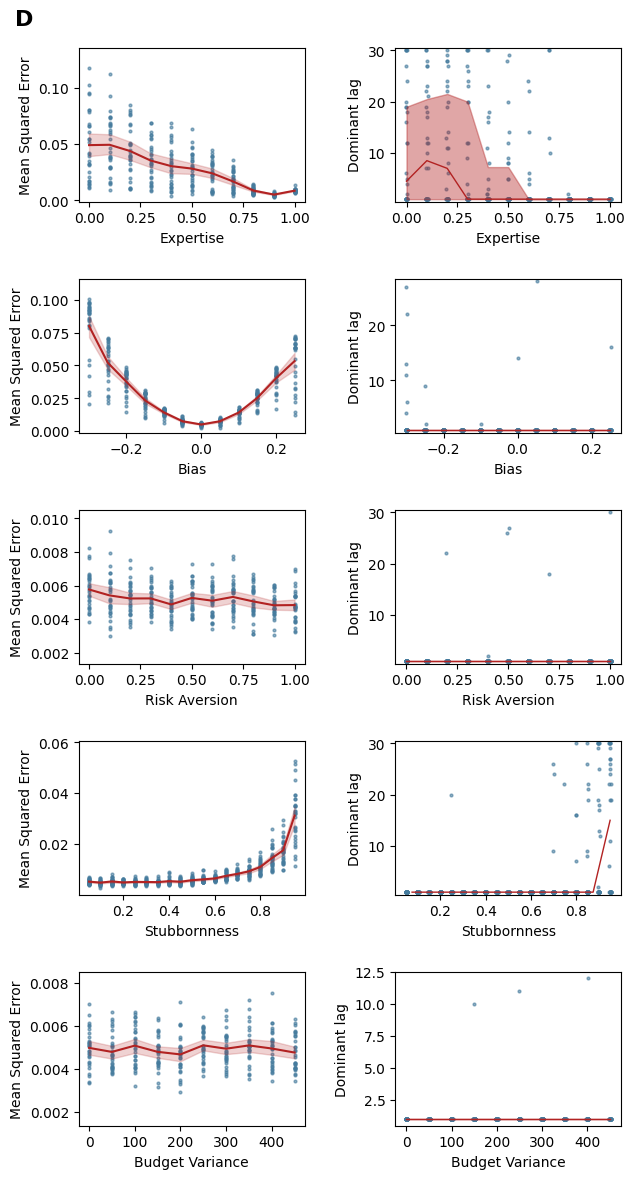

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

fig, ax = plt.subplots(len(results_dict.keys()), 2, figsize=(7, 14))
plt.subplots_adjust(hspace=0.5, wspace=0.4)
axs = ax.ravel()

i = 0
for k in results_dict.keys():
    if k == 'Exponetial budget':
        continue

    arr = results_dict[k]
    params = arr[:, 0]
    mse = arr[:, 1]

    # Left: MSE (same as before)
    axs[i].scatter(x=params, y=mse, s=4, alpha=0.6,color='#457B9D')
    sns.lineplot(x=params, y=mse, ax=axs[i], color='#B22222')
    axs[i].set_xlabel(k.replace("_"," ").title())
    axs[i].set_ylabel('Mean Squared Error')
    y1, y2 = axs[i].get_ylim()
    axs[i].set_ylim(0.5 * y1, 1.1 * y2)

    i += 1

    dominant_lag = arr[:, 2]

    # Jitter scatter for readability
    jitter = (np.random.rand(len(params)) - 0.5) * ( (np.max(params) - np.min(params)) * 0.01 + 1e-6 )
    axs[i].scatter(x=params + jitter, y=dominant_lag, s=4, alpha=0.6, color='#457B9D')

    # Summary line: compute median and IQR in parameter bins
    df = pd.DataFrame({'param': params, 'lag': [int(x) for x in dominant_lag]})
    # choose bins: if param has few unique values, use them; otherwise use quantile bins
    if len(np.unique(params)) <= 12:
        # group by unique param values
        grp = df.groupby('param')
        print(grp)
        x_centers = np.array(list(grp.groups.keys()))
        med = grp['lag'].median().values
        q1 = grp['lag'].quantile(0.25).values
        q3 = grp['lag'].quantile(0.75).values
    else:
        # use 12 even quantile bins
        df['bin'] = pd.qcut(df['param'], q=12, duplicates='drop')
        grp = df.groupby('bin')
        # x center for each bin
        x_centers = grp['param'].median().values
        med = grp['lag'].median().values
        q1 = grp['lag'].quantile(0.25).values
        q3 = grp['lag'].quantile(0.75).values

    # Plot median line and IQR shading
    axs[i].plot(x_centers, med, color='#B22222', linewidth=1)

    try:
        axs[i].fill_between(x_centers, q1, q3, color='#B22222', alpha=0.4, step=None)
    except:
        pass

    axs[i].set_xlabel(k.replace("_"," ").title())
    axs[i].set_ylabel('Dominant lag')
    # tighten y-limits with small margin
    y_min, y_max = np.min(dominant_lag), np.max(dominant_lag)
    axs[i].set_ylim(max(y_min - 0.5, -0.5), y_max + 0.5)

    i += 1

plt.text(-0.2, 1.25, 'D', transform=axs[0].transAxes,
           fontsize=16, fontweight='bold', va='top', ha='right')
plt.savefig('New_P1_results_combined.pdf', bbox_inches='tight')
plt.show()


In [ ]:
# Global parameters

N_bettors = 100
T_max = 100
initial_price = 0.5
rw_variance = 0.05

# number of iterations for each set of parameters
n_iter_ = 3

# Set initial input values to the betting market function
parameters = {'n_bettors': N_bettors, # The number of betting agents
                #'el_outcome': 1, # Q: Ultimate election outcome - assuming we know this to begin with and it does not change over time...for now this is implemented as a random walk of the probability...but should this be 0 or 1 instead? '''
            't_election': T_max, # Time until election takes place (ie. time horizon of betting)
            'initial_price': initial_price, # Initial market price (is this equivalent to probability of winning)
            'outcome_uncertainty': rw_variance} # This is a measure of how uncertain the true outcome is - ie. the volatility of the random walk election probability

parameters.update({'bettors': [bettor(budget=100) for _ in range(parameters['n_bettors'])] + [bettor(budget=200, market_valuation=1,whale=True)]})


In [ ]:
market_record = run_market(**parameters)

In [ ]:

val_col = "#B788E5"
el_col = "#E63946"
def plot_returns(rec, scale_fact = 10, step=False): ## Election Result

    # process market pressure
    mp =  np.array(rec['market_pressure'])[1:]
    upward_pressure = rec['price_history'][:-1] +  ([mp>0] * mp)[0]/scale_fact # positive market pressure
    downward_pressure = rec['price_history'][:-1]  + ([mp<0] * mp)[0]/scale_fact # negative market pressure
    N = len(rec["price_history"])

    fig, ax = plt.subplots(2,figsize=[8,7])
    plt.subplots_adjust(hspace=-5)

    if step:
        ax[0].plot(rec['price_history'], color = "black", label = "Market price", drawstyle = "steps")
        ax[0].fill_between(range(N-1), upward_pressure, rec['price_history'][:-1], color = "darkorange", alpha = 0.5, step = 'pre', label="Upward Pressure")
        ax[0].fill_between(range(N-1), downward_pressure, rec['price_history'][:-1], color = "dodgerblue", alpha = 0.5, step = 'pre', label="Downward Pressure")


        ax[0].plot(rec['gen_el'], color = el_col, label = "Election outcome", drawstyle = "steps")
        ax[0].plot(rec['beliefs'], color = val_col, label = "Average market valuation", drawstyle = "steps", linewidth=1.2)


        # volume and net supply
        ax[1].plot(rec['vol_history'], color = '#1D3557', label = "No. of Contracts", drawstyle = "steps")
        ax[1].plot(rec['net_supply'], color = "#339966", linestyle = "dashed", label = "Net Supply and Demand", drawstyle = "steps")

    else:
        ax[0].plot(rec['price_history'], color = "black", label = "Market price")
        ax[0].fill_between(range(N-1), upward_pressure, rec['price_history'][:-1], color = "darkorange", alpha = 0.5)
        ax[0].fill_between(range(N-1), downward_pressure, rec['price_history'][:-1], color = "dodgerblue", alpha = 0.5)


        ax[0].plot(rec['gen_el'], color = el_col, label = "Election outcome")
        ax[0].plot(rec['beliefs'], color = val_col, linestyle = "dotted", label = "Average market valuation")


        # volume and net supply
        ax[1].plot(rec['vol_history'], color = el_col, label = "No. of Contracts")
        ax[1].plot(rec['net_supply'], color = "#457B9D", linestyle = "dashed", label = "Net Supply")

    ax[0].set_ylim(0,1.02)
    # change order of legend entries in ax[0] 
    handles, labels = ax[0].get_legend_handles_labels()
    order = [0,2,3,1,4]  # example order, adjust as needed
    ax[0].legend([handles[idx] for idx in order], [labels[idx] for idx in order], loc = "lower center", bbox_to_anchor=(0.5, -.6), ncols=3)


    ax[1].legend(loc = "lower center", bbox_to_anchor=(0.5, -0.6), ncols=2)

    ax[0].set_title('Market Price')
    ax[1].set_title('Contract Volume & Net Supply')

    ax[0].set_xlabel('Time')
    ax[1].set_xlabel('Time')
    ax[0].set_ylabel('Result')
    ax[1].set_ylabel('Result')
    plt.xticks(rotation=45)
    fig.tight_layout()

    # Display the plot

    plt.text(-0.065, 1.25, 'A', transform=ax[0].transAxes,
            fontsize=16, fontweight='bold', va='top', ha='right')
    
    plt.text(-0.065, 1.25, 'B', transform=ax[1].transAxes,
            fontsize=16, fontweight='bold', va='top', ha='right')
    plt.savefig('New_market_run.pdf', bbox_inches='tight')


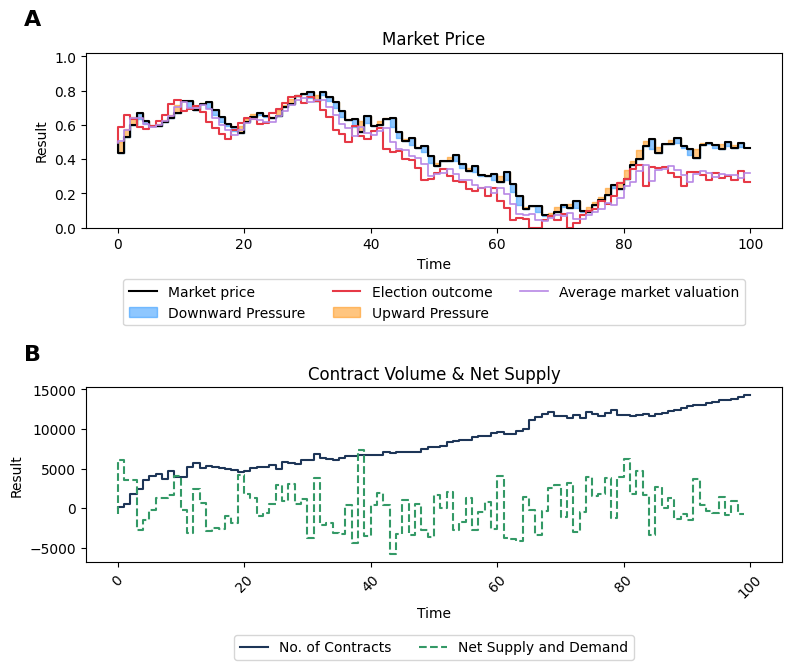

In [ ]:
plot_returns(market_record, scale_fact=15, step=True)

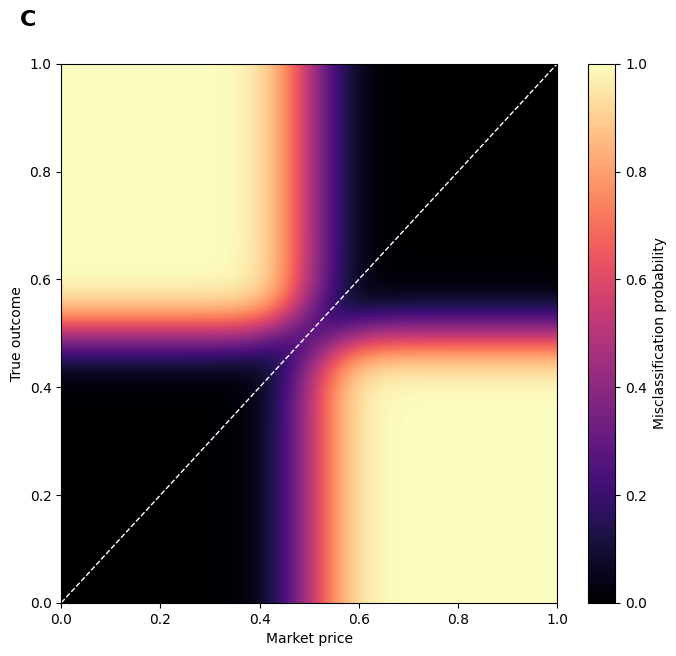

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, multivariate_normal

def misclassification_prob(mu_m, mu_eta, sigma_m, sigma_eta, rho):
    """
    Compute P((m-0.5)(eta-0.5) < 0) for (m,eta) ~ bivariate normal
    with means mu_m, mu_eta; std devs sigma_m, sigma_eta; correlation rho.
    """
    # Standardised thresholds
    a = (0.5 - mu_m) / sigma_m
    b = (0.5 - mu_eta) / sigma_eta
    
    # Univariate cdfs
    Phi_a = norm.cdf(a)
    Phi_b = norm.cdf(b)
    
    # Bivariate CDF at (a,b) with correlation rho
    # multivariate_normal.cdf gives P(X <= a, Y <= b) for mean=0 cov with corr rho.
    cov = np.array([[1.0, rho], [rho, 1.0]])
    # Note: multivariate_normal.cdf accepts array_like inputs; do scalar call:
    Phi2_ab = multivariate_normal.cdf([a, b], mean=[0.0, 0.0], cov=cov)
    
    # formula
    p = Phi_a + Phi_b - 2.0 * Phi2_ab
    return p

# ----------------------------
# Parameters and grid
# ----------------------------
sigma_m = 0.07     # std dev of market price
sigma_eta = 0.05   # std dev of true outcome (uncertainty)
rho = 0.6          # correlation between m and eta (choose 0..1)
n = 201

mu_m_grid = np.linspace(0.0, 1.0, n)     # x-axis (market price centers)
mu_eta_grid = np.linspace(0.0, 1.0, n)   # y-axis (true outcome centers)

P = np.zeros((n, n))
for i, mu_eta in enumerate(mu_eta_grid):
    for j, mu_m in enumerate(mu_m_grid):
        P[i, j] = misclassification_prob(mu_m, mu_eta, sigma_m, sigma_eta, rho)

# ----------------------------
# Plot heatmap
# ----------------------------
fig, ax = plt.subplots(figsize=(8,7))
im = ax.imshow(
    P,
    origin='lower',
    extent=[mu_m_grid[0], mu_m_grid[-1], mu_eta_grid[0], mu_eta_grid[-1]],
    aspect='auto',
    cmap='magma',
    vmin=0, vmax=1
)
ax.set_xlabel('Market price')
ax.set_ylabel('True outcome')
# ax.set_title('P((m-0.5)(\\eta-0.5) < 0) (misclassification probability)')
cbar = fig.colorbar(im, ax=ax)
cbar.set_label('Misclassification probability')
# Add diagonal reference line where mu_m = mu_eta
ax.plot([0,1],[0,1], color='white', linestyle='--', linewidth=1)

plt.text(-0.05, 1.1, 'C', transform=ax.transAxes,
           fontsize=16, fontweight='bold', va='top', ha='right')
plt.savefig('F1_misclassification_prob_heatmap.pdf')


# Plot 2 - Whales

(A) normalised profit for non-whale N_bettors

(B) MSE for whales

(C) shock error

In [ ]:
# Global parameters

N_bettors = 100
T_max = 200
initial_price = 0.5
rw_variance = 0.05

In [ ]:
n_iter_=100

In [ ]:
# Set initial input values to the betting market function
parameters = {'n_bettors': N_bettors, # The number of betting agents
                #'el_outcome': 1, # Q: Ultimate election outcome - assuming we know this to begin with and it does not change over time...for now this is implemented as a random walk of the probability...but should this be 0 or 1 instead? '''
            't_election': T_max, # Time until election takes place (ie. time horizon of betting)
            'initial_price': initial_price, # Initial market price (is this equivalent to probability of winning)
            'outcome_uncertainty': rw_variance} # This is a measure of how uncertain the true outcome is - ie. the volatility of the random walk election probability


# expertise_values = np.linspace(0,1,N_bettors)

av_budget=100
budget_total = av_budget* N_bettors
N_whales = 1
whale_valuation = 0.6

prop_whale=0.5

expertise_whale = {}

for whale_valuation in [0.6,0.7,0.8]:
    
    whale_effect = []

    whale_budget = av_budget*N_bettors*prop_whale / (1-prop_whale)

    non_whale_bettors = [bettor(budget=av_budget, expertise=0.9) for i in range(N_bettors)]
    whale_bettors = [bettor(budget=whale_budget, whale=True, market_valuation=whale_valuation) for _ in range(N_whales)]

    parameters.update({'bettors': non_whale_bettors + whale_bettors})

    for _ in range(n_iter_):
        market_record = run_market(**parameters)

        whale_effect.append((np.array(market_record['price_history']) -  np.array(market_record['gen_el'])))

    expertise_whale[whale_valuation] = whale_effect

In [ ]:
times = np.arange(T_max+1)
vals = []
for k,val in expertise_whale.items():
    for v in val:
        for x in range(T_max+1):
            vals.append([k,v[x],times[x]])


df_plot = pd.DataFrame(vals, columns = ['W','SE','T'])

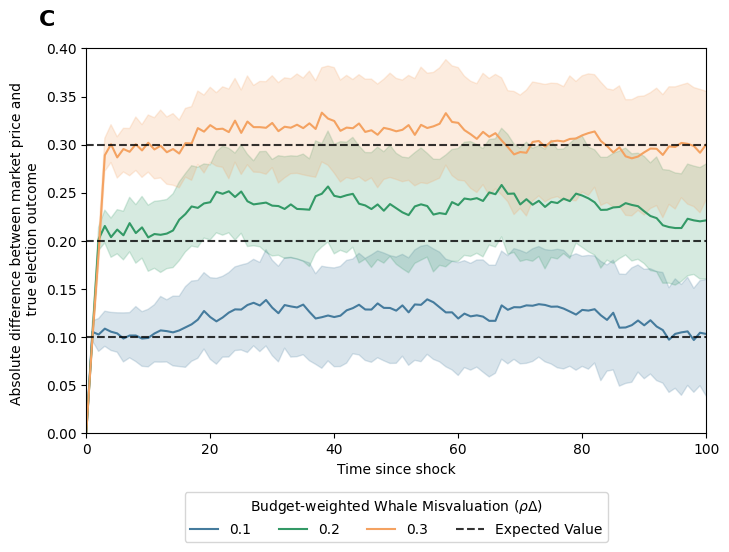

In [ ]:
plt.figure(figsize=[8, 5])

sns.lineplot(data = df_plot, x='T', y='SE',hue='W', palette = ["#457B9D", "#339966", "#F4A261"], linewidth=1.5)
plt.xlabel('Time since shock')

plt.ylabel('Absolute difference between market price and \n true election outcome')

# clip axhlines to max at 500
plt.axhline(0.2, color='black', linestyle='--', alpha=0.8)
plt.axhline(0.1, color='black', linestyle='--', alpha=0.8)
plt.axhline(0.3, color='black', linestyle='--', label='Expected Value', alpha=0.8)

# round labels in legend to 1dp
# get current legend
legend = plt.gca().get_legend()
for text in legend.get_texts():
    text.set_text(f"{float(text.get_text()):.1f}")

plt.xlim(0,100)
# move legend
plt.ylim(0,0.4)
# plt.legend(title = 'Valuation of Whale', loc='upper right')
# put legend below x axis
plt.legend( loc='lower center',ncol=4,bbox_to_anchor=(0.5,-0.3),title=r'Budget-weighted Whale Misvaluation $(\rho \Delta)$')

# change legend labels
legend = plt.gca().get_legend()
new_labels = ['0.1', '0.2', '0.3']
for text, new_label in zip(legend.get_texts(), new_labels):
    text.set_text(new_label)

plt.text(-0.05, 1.1, 'C', transform=plt.gca().transAxes,
           fontsize=16, fontweight='bold', va='top', ha='right')
plt.savefig('F2_TheoreticalAgreement.pdf', bbox_inches='tight')

## expertise

In [ ]:
with open('expertise_whale.pkl','rb') as f:
    expertise_whale = pickle.load(f)

In [ ]:
props = list(expertise_whale.keys())
props.sort()

In [ ]:
# dataframe from dict
import pandas as pd
df_list = []
for k,v in expertise_whale.items():
    df_temp = pd.DataFrame({'expertise':list(flatten(v[0])), 'budgets':list(flatten(v[2])), 'prop_whale':[k for _ in range(len(list(flatten(v[0]))))]})
    df_list.append(df_temp)

# make a single dataframe
df_list = pd.concat(df_list, ignore_index=True)

In [ ]:
for g, df_ in df_list.groupby('prop_whale'):
    print(f'Min expertise for a normalised profit above 0.1: {round(g,2)}, {round(np.min(df_[df_.budgets>0.1].expertise),4)}')

    # Compute cumulative budget share
    df_["cum_budget_share"] = df_["budgets"].cumsum() / df_["budgets"].sum()

    print("Expertise threshold for 10% of normalised profit:", round(df_.loc[df_["cum_budget_share"] >= 0.1].expertise.values[0],3))

Min expertise for a normalised profit above 0.1: 0.0, 0.899
Expertise threshold for 10% of normalised profit: 0.0
Min expertise for a normalised profit above 0.1: 0.02, 0.6566
Expertise threshold for 10% of normalised profit: 0.838
Min expertise for a normalised profit above 0.1: 0.05, 0.6566
Expertise threshold for 10% of normalised profit: 0.98
Min expertise for a normalised profit above 0.1: 0.08, 0.1313
Expertise threshold for 10% of normalised profit: 0.808
Min expertise for a normalised profit above 0.1: 0.1, 0.7576
Expertise threshold for 10% of normalised profit: 0.859
Min expertise for a normalised profit above 0.1: 0.2, 0.4141
Expertise threshold for 10% of normalised profit: 0.909
Min expertise for a normalised profit above 0.1: 0.3, 0.6667
Expertise threshold for 10% of normalised profit: 0.667
Min expertise for a normalised profit above 0.1: 0.4, 0.4848
Expertise threshold for 10% of normalised profit: 1.0
Min expertise for a normalised profit above 0.1: 0.5, 0.0303
Expert

In [ ]:
# get weighted average expertise by budget for each prop_whale
weighted_expertise = df_list.groupby('prop_whale').apply(lambda x: np.average(x['expertise'], weights=x['budgets'])).reset_index()
weighted_expertise.columns = ['prop_whale', 'weighted_expertise']

/var/folders/wp/758jq81s3hs0jlp8_31261sc0000gn/T/ipykernel_85387/2062336582.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  weighted_expertise = df_list.groupby('prop_whale').apply(lambda x: np.average(x['expertise'], weights=x['budgets'])).reset_index()


In [ ]:
colors_sorted = [
    # "#000080",  # darkest
    # "#1D3557",
    "#8865B8",
    "#339966",
    "#457B9D",
    "#2A9D8F",
    "#B22222",
    "#E63946",
    "#F4A261",
    "#FFB347",
    "#CC99FF"   # lightest
]
# define mpl colourmap

/var/folders/wp/758jq81s3hs0jlp8_31261sc0000gn/T/ipykernel_85387/3219026188.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax=sns.boxplot(data=df_list[df_list['expertise']>=0.5], x='prop_whale', y='budgets', palette = colors_sorted, fliersize=1)


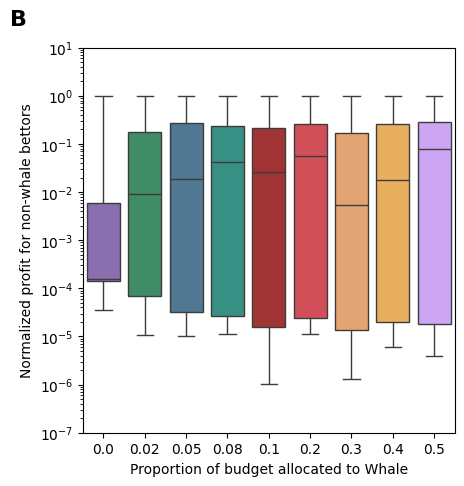

In [ ]:
# set up box plot
plt.figure(figsize=(4.8,5))
plt.yscale('log')
# make marker size smaller
ax=sns.boxplot(data=df_list[df_list['expertise']>=0.5], x='prop_whale', y='budgets', palette = colors_sorted, fliersize=1)
for patch in ax.artists:
    patch.set_alpha(0.2) 
plt.xlabel('Proportion of budget allocated to Whale')
plt.ylabel('Normalized profit for non-whale bettors')

# round xtick labels to 1dp
plt.xticks(ticks=np.arange(len(props)), labels=[round(x, 2) for x in props])
plt.ylim(1e-7,10)

plt.text(-0.15, 1.1, 'B', transform=plt.gca().transAxes,
           fontsize=16, fontweight='bold', va='top', ha='right')
plt.savefig('expertise_whale_boxplot.pdf', bbox_inches='tight')

In [ ]:
mv=0.6
N=100

In [ ]:

r_arr = np.array(results)
with open(f'whale_{mv}_{N}.pkl', 'rb') as f:
    results = pickle.load(f)


results[:,2] = [x['lag'] for x in results[:,2]]

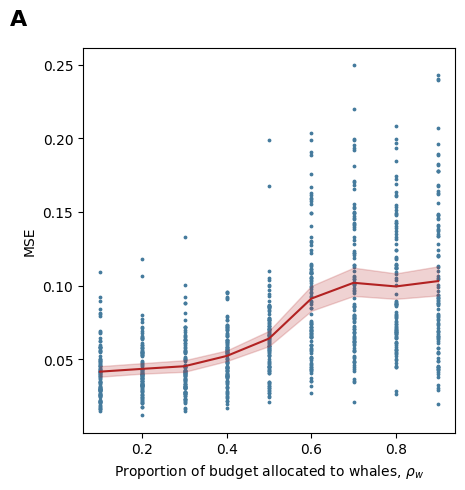

In [ ]:

# modify the simulation to multiprocess
fig,ax = plt.subplots(figsize=(4.8,5))
ax.scatter(x=results[:,0],y=results[:,1],s=3,c='#457B9D')
sns.lineplot(x=results[:,0],y=results[:,1],c='#B22222',ax=ax)
ax.set_ylabel('MSE')
ax.set_xlabel(r'Proportion of budget allocated to whales, $\rho_w$')
# plt.suptitle(f'Single whale with internal valuation of {mv}')
plt.text(-0.15, 1.1, 'A', transform=plt.gca().transAxes,
           fontsize=16, fontweight='bold', va='top', ha='right')
plt.savefig(f'whales_{mv}_{N}.pdf', bbox_inches='tight')

In [ ]:
ax[0,0]

<Axes: >

/var/folders/wp/758jq81s3hs0jlp8_31261sc0000gn/T/ipykernel_85387/1508112071.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_list[df_list['expertise']>=0.5], x='prop_whale', y='budgets', palette = colors_sorted, fliersize=1, ax=ax01)


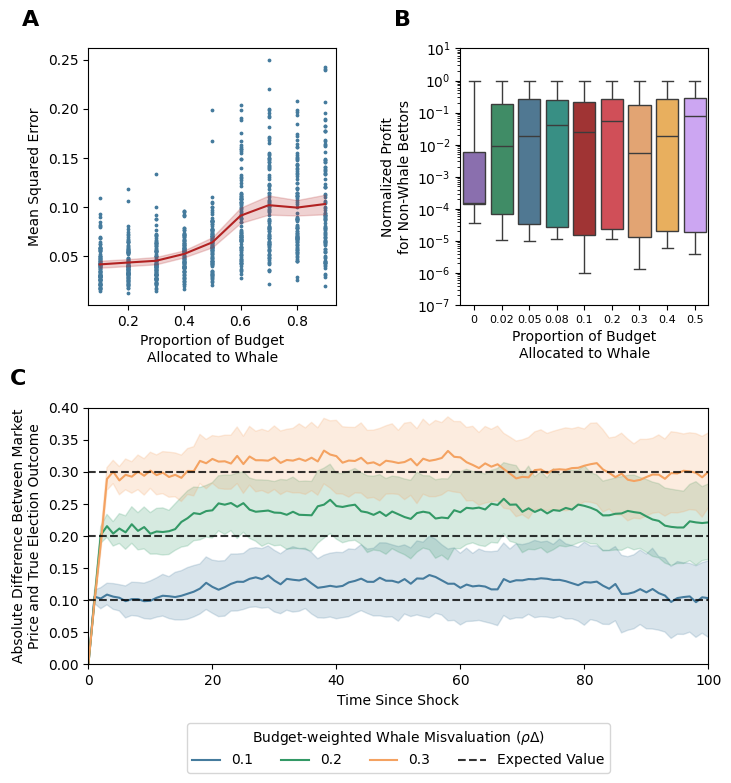

In [ ]:
# make figure with 4 subplots
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(8,8))
gs = gridspec.GridSpec(2, 2, height_ratios=[1,1], hspace=0.4, wspace=0.5)

# top-left
ax00 = fig.add_subplot(gs[0,0])
# top-right
ax01 = fig.add_subplot(gs[0,1])
# bottom combined (spans both columns)
ax10 = fig.add_subplot(gs[1, :])   # ← spans columns 0 and 1
# axs = ax.ravel()

# subplot 1 
ax00.scatter(x=results[:,0],y=results[:,1],s=3,c='#457B9D')
sns.lineplot(x=results[:,0],y=results[:,1],c='#B22222',ax=ax00)
ax00.set_ylabel('Mean Squared Error')
ax00.set_xlabel('Proportion of Budget\nAllocated to Whale')
# plt.suptitle(f'Single whale with internal valuation of {mv}')
plt.text(-0.2, 1.15, 'A', transform=ax00.transAxes,
           fontsize=16, fontweight='bold', va='top', ha='right')

# subplot 2
ax01.set_yscale('log')
# make marker size smaller
sns.boxplot(data=df_list[df_list['expertise']>=0.5], x='prop_whale', y='budgets', palette = colors_sorted, fliersize=1, ax=ax01)
for patch in ax01.artists:
    patch.set_alpha(0.2) 
ax01.set_xlabel('Proportion of Budget\nAllocated to Whale')
ax01.set_ylabel('Normalized Profit\nfor Non-Whale Bettors')
# round xtick labels to 1dp
ax01.set_xticks(ticks=np.arange(len(props)))
ax01.set_xticklabels([f"{p:.1g}" for p in props], fontsize=8)
ax01.set_ylim(1e-7,10)

plt.text(-0.2, 1.15, 'B', transform=ax01.transAxes,
           fontsize=16, fontweight='bold', va='top', ha='right')

# combine bottom two axes

sns.lineplot(data = df_plot, x='T', y='SE',hue='W', palette = ["#457B9D", "#339966", "#F4A261"], linewidth=1.5, ax=ax10)
ax10.set_xlabel('Time Since Shock')

ax10.set_ylabel('Absolute Difference Between Market\nPrice and True Election Outcome')

# clip axhlines to max at 500
ax10.axhline(0.2, color='black', linestyle='--', alpha=0.8)
ax10.axhline(0.1, color='black', linestyle='--', alpha=0.8)
ax10.axhline(0.3, color='black', linestyle='--', label='Expected Value', alpha=0.8)

# round labels in legend to 1dp
# get current legend
legend = ax10.get_legend()
for text in legend.get_texts():
    text.set_text(f"{float(text.get_text()):.1f}")

ax10.set_xlim(0,100)
# move legend
ax10.set_ylim(0,0.4)
# ax10.set_legend(title = 'Valuation of Whale', loc='upper right')
# put legend below x axis
ax10.legend( loc='lower center',ncol=4,bbox_to_anchor=(0.5,-0.45),title=r'Budget-weighted Whale Misvaluation $(\rho \Delta)$')

# change legend labels
legend = plt.gca().get_legend()
new_labels = ['0.1', '0.2', '0.3']
for text, new_label in zip(legend.get_texts(), new_labels):
    text.set_text(new_label)

plt.text(-0.1, 1.15, 'C', transform=ax10.transAxes,
           fontsize=16, fontweight='bold', va='top', ha='right')

plt.savefig('Figure2.pdf', bbox_inches='tight')

# Figure 3

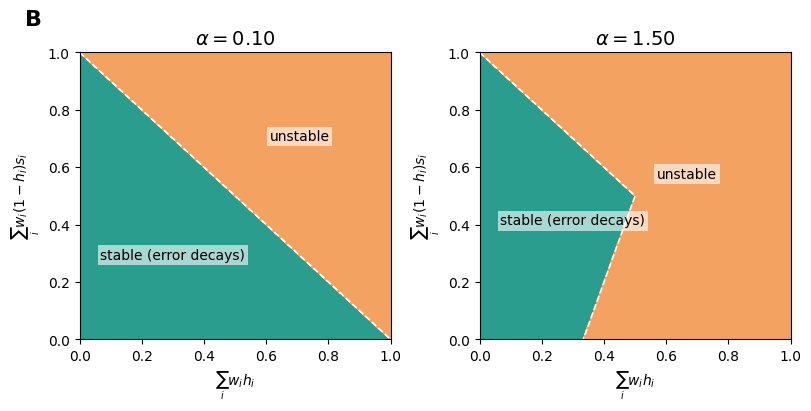

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def compute_roots_and_rho(alpha, H_mesh, S_mesh):
    tr = (1.0 - alpha) + S_mesh
    det = (1.0 - alpha) * S_mesh - alpha * H_mesh
    disc = tr**2 - 4.0 * det
    sqrt_disc = np.sqrt(disc.astype(np.complex128))
    r1 = 0.5 * (tr + sqrt_disc)
    r2 = 0.5 * (tr - sqrt_disc)
    rho = np.maximum(np.abs(r1), np.abs(r2)).real
    unstable = rho >= 1.0 - 1e-12
    oscillatory = (np.abs(np.imag(r1)) > 1e-9) | (np.abs(np.imag(r2)) > 1e-9)
    region = np.zeros_like(rho, dtype=int)     # 0 stable monotone, 1 stable oscillatory, 2 unstable
    region[oscillatory & (~unstable)] = 1
    region[unstable] = 2
    return rho, region, r1, r2

# ---- Grid and alphas ----
res = 301
h = np.linspace(0, 1, res)
s = np.linspace(0, 1, res)
H_mesh, S_mesh = np.meshgrid(h, s, indexing='xy')

alpha_list = [0.10, 1.50]   # two panels (change as desired)

# ---- Points to mark (replace with your 4 test points) ----
# Example placeholders (you will replace these with the 4 points you will run):
points = [
    (0.94, 0.06),  # p1 (whale near-boundary)
    (0.10, 0.10),  # p2 (stable homogeneous)
    (0.67, 0.00)   # p3 (crossing homogeneous)
]
point_labels = ['p3', 'p1', 'p2']
point_colors = ['red', 'green', 'blue']
# ---- Compute grids ----
results = [compute_roots_and_rho(alpha, H_mesh, S_mesh) for alpha in alpha_list]
rho_list = [r[0] for r in results]
region_list = [r[1] for r in results]
r1_list = [r[2] for r in results]
r2_list = [r[3] for r in results]

# ---- Plotting ----
fig, axes = plt.subplots(1, len(alpha_list), figsize=(8, 4), constrained_layout=True)

region_colors = {0: '#2A9D8F', 1: '#F4A261', 2: '#F4A261'}  # green, orange, red

for idx, (ax, alpha, rho, region, r1_grid, r2_grid) in enumerate(zip(axes, alpha_list, rho_list, region_list, r1_list, r2_list)):
    # plot region fills (solid blocks as you had)
    ax.contourf(h, s, (region==0).astype(int), levels=[0.5,1.5], colors=[region_colors[0]], alpha=1.0)
    ax.contourf(h, s, (region==1).astype(int), levels=[0.5,1.5], colors=[region_colors[1]], alpha=1.0)
    ax.contourf(h, s, (region==2).astype(int), levels=[0.5,1.5], colors=[region_colors[2]], alpha=1.0)

    # contour where spectral radius == 1 for visual boundary
    ax.contour(h, s, rho, levels=[1.0], colors='white', linewidths=1.2, linestyles='--')

    # label the green and red regions by computing centroid (mean of coordinates where mask True)
    for code, label_text in [(0, 'stable (error decays)'), (2, 'unstable')]:
        mask = (region == code)
        if mask.any():
            # find centroid coordinates for placement (use median to be robust)
            ys, xs = np.where(mask)   # indices in grid coordinates
            # convert indices to actual h,s coordinates (grid is indexing='xy')
            mean_h = h[int(np.median(xs))]
            mean_s = s[int(np.median(ys))]
            # small shifts to avoid clipping near edges
            mean_h = np.clip(mean_h, 0.3, 0.95)
            mean_s = np.clip(mean_s, 0.1, 0.95)
            ax.text(mean_h, mean_s, label_text, fontsize=10,
                    ha='center', va='center', color='k', bbox=dict(facecolor='white', alpha=0.6, edgecolor='none', pad=2))

    # plot the 3 points and print their theoretical roots for this alpha
    # print(f"\n--- alpha = {alpha:.6f} ---")
    # for p_idx, (ph, ps) in enumerate(points, start=1):
    #     # find nearest grid location to sample r1/r2/rho
    #     ih = int(np.clip(np.searchsorted(h, ph), 0, len(h)-1))
    #     is_ = int(np.clip(np.searchsorted(s, ps), 0, len(s)-1))
    #     r1_val = r1_grid[is_, ih]
    #     r2_val = r2_grid[is_, ih]
    #     rho_val = rho[is_, ih]
    #     print(f"[alpha={alpha:.6f}] {point_labels[p_idx-1]}: (H^B={ph:.3f}, S_w={ps:.3f}) -> rho={rho_val:.6f}, r1={r1_val:.6f}, r2={r2_val:.6f}")
    #     # annotate on plot
    #     ax.scatter([ph], [ps], s=120, c=point_colors[p_idx-1], edgecolor='k', zorder=10)
    #     ax.text(ph+0.015, ps+0.015, f"{point_labels[p_idx-1]}", fontsize=10, fontweight='bold',
    #             color='k', bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1))
        
    # plot the 4 test points and compute/print their spectral quantities for this alpha
    # for p_idx, (ph, ps) in enumerate(points, start=1):
    #     # find nearest grid location to sample r1/r2/rho
    #     ih = int(np.clip(np.searchsorted(h, ph), 0, len(h)-1))
    #     is_ = int(np.clip(np.searchsorted(s, ps), 0, len(s)-1))
    #     r1_val = r1_grid[is_, ih]
    #     r2_val = r2_grid[is_, ih]
    #     rho_val = rho[is_, ih]
    #     # print to console
    #     print(f"[alpha={alpha:.2f}] p{p_idx}: (H^B={ph:.3f}, S_w={ps:.3f}) -> rho={rho_val:.6f}, r1={r1_val:.6f}, r2={r2_val:.6f}")
    #     # annotate on plot
    #     ax.plot(ph, ps, marker='o', markersize=8, markeredgecolor='k', markerfacecolor='white')
    #     ax.text(ph+0.02, ps+0.02, f"p{p_idx}", fontsize=9, fontweight='bold', color='k',
    #             bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1))


    ax.set_title(r'$\alpha={:.2f}$'.format(alpha), fontsize=14)
    ax.set_xlabel(r'$\sum_i w_i h_i$')
    ax.set_ylabel(r'$\sum_i w_i (1-h_i) s_i$')
    ax.set_xlim(0,1)
    ax.set_ylim(0,1)


axes[0].text(-0.12, 1.15, 'C',
             transform=axes[0].transAxes,
             fontsize=16, fontweight='bold',
             va='top', ha='right')


# plt.suptitle('Stability regions (shaded). White dashed contour: |r|=1\nMarkers p1..p4 show test points; console prints values', fontsize=12)
plt.savefig('F3_stability_regions_marked_points.pdf', bbox_inches='tight')


In [ ]:
## set up for herding box plot